<a href="https://colab.research.google.com/github/Ars1234qwer/Ultimate-F1-guide/blob/main/ArsalaanFA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Set up and  data loading

### Importing libraries

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


###  google drive connection



In [58]:
# connect to google drive
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [59]:
# cd
%cd /content/drive/MyDrive/05. Final Assignment (due Nov 28)/Final Assignment/

/content/drive/.shortcut-targets-by-id/1ukp7rSVVg-S0BMNehL5PZniqr5qSyXZh/05. Final Assignment (due Nov 28)/Final Assignment


### loading two source tables

In [60]:
import os
from pathlib import Path

current_dir = Path(os.getcwd())

client_path = current_dir / "telecom" / "Client.csv"
record_path = current_dir / "telecom" / "Record.csv"

for p in (client_path, record_path):
  print(p.exists())

client = pd.read_csv(client_path)
record = pd.read_csv(record_path)

print(client.shape)
print(record.shape)

True
True
(100000, 50)
(100000, 51)


### Validating customer ID

In [61]:
# checking duplicate customer ID
print(client['Customer_ID'].duplicated().sum())

# checking missing customer ID
print(client['Customer_ID'].isnull().sum())

0
0


### Merging both datasets

In [62]:
# merging both datasets
df = pd.merge(client, record, on='Customer_ID', how='inner')
print(df.shape)
df.head()

(100000, 100)


,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,...,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months
0,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,...,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61
1,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,...,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56
2,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,...,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58
3,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,...,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60
4,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,...,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57


## EDA

### Shapes and types

In [63]:
df.info(verbose=False)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Columns: 100 entries, uniqsubs to months
dtypes: float64(69), int64(10), object(21)
memory usage: 76.3+ MB


### Missing values

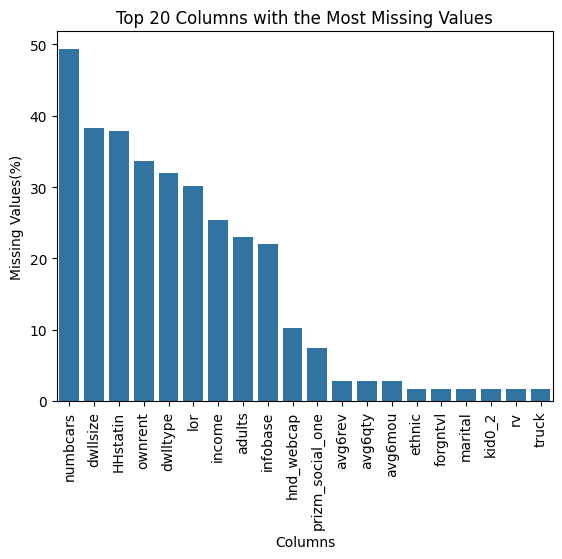

In [64]:
# first finding out how much values(percentage) are missing in each column
missing_count_percentage = df.isnull().sum() / len(df) * 100

# taking the top 20 columns with the  most missing values
top = missing_count_percentage.sort_values(ascending=False).head(20)

# Plot (vertical bars)
sns.barplot(x=top.index, y=top.values)
plt.xlabel('Columns')
plt.ylabel('Missing Values(%)')
plt.title('Top 20 Columns with the Most Missing Values')
plt.xticks(rotation=90)
plt.show()

### Target Variable (churn)

In [65]:
# cheking for unique target values (confirming binary classification)
print


       uniqsubs  actvsubs new_cell crclscod asl_flag  totcalls       totmou  \
0             2         1        U        A        N      1652   4228.00000   
1             1         1        N       EA        N     14654  26400.00000   
2             1         1        Y        C        N      7903  24385.05333   
3             1         1        Y        B        N      1502   3065.00000   
4             1         1        Y        A        N      4485  14028.00000   
...         ...       ...      ...      ...      ...       ...          ...   
99995         1         1        U        B        N      3771   9534.00000   
99996         1         1        U       CY        Y      3675   8887.00000   
99997         1         1        U       DA        N      1271   9336.00000   
99998         1         1        U       EA        N     10082  20784.00000   
99999         1         1        U        B        N      1303   2355.00000   

        totrev   adjrev    adjmou  ...  opk_dat_Mea